# Machine Learning - Practical 1 - Linear Regression

**Authors:** Muhammed Nagaş, Felix Fischer, Niclas Langer  
Summer term 2026

*Machine Learning course, University of Göttingen, summer term 2026. The exercise template (task text, helper code) was provided by the course; the solutions and answers are ours.*

In [1]:
%matplotlib inline

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn import linear_model
from sklearn.metrics import mean_squared_error, r2_score

## The  dataset

The dataset consists of over 20.000 materials and lists their physical features. From these features, we want to learn how to predict the critical temperature, i.e. the temperature we need to cool the material to so it becomes superconductive. First load and familiarize yourself with the data set a bit.

In [2]:
data = pd.read_csv('../data/superconduct_train.csv')
print(data.shape)

(21263, 82)


In [3]:
data.head()

,number_of_elements,mean_atomic_mass,wtd_mean_atomic_mass,gmean_atomic_mass,wtd_gmean_atomic_mass,entropy_atomic_mass,wtd_entropy_atomic_mass,range_atomic_mass,wtd_range_atomic_mass,std_atomic_mass,...,wtd_mean_Valence,gmean_Valence,wtd_gmean_Valence,entropy_Valence,wtd_entropy_Valence,range_Valence,wtd_range_Valence,std_Valence,wtd_std_Valence,critical_temp
0,4,88.944468,57.862692,66.361592,36.116612,1.181795,1.062396,122.90607,31.794921,51.968828,...,2.257143,2.213364,2.219783,1.368922,1.066221,1,1.085714,0.433013,0.437059,29.0
1,5,92.729214,58.518416,73.132787,36.396602,1.449309,1.057755,122.90607,36.161939,47.094633,...,2.257143,1.888175,2.210679,1.557113,1.047221,2,1.128571,0.632456,0.468606,26.0
2,4,88.944468,57.885242,66.361592,36.122509,1.181795,0.975980,122.90607,35.741099,51.968828,...,2.271429,2.213364,2.232679,1.368922,1.029175,1,1.114286,0.433013,0.444697,19.0
3,4,88.944468,57.873967,66.361592,36.119560,1.181795,1.022291,122.90607,33.768010,51.968828,...,2.264286,2.213364,2.226222,1.368922,1.048834,1,1.100000,0.433013,0.440952,22.0
4,4,88.944468,57.840143,66.361592,36.110716,1.181795,1.129224,122.90607,27.848743,51.968828,...,2.242857,2.213364,2.206963,1.368922,1.096052,1,1.057143,0.433013,0.428809,23.0


Because the dataset is rather large, we prepare a small subset of the data as training set, and another subset as test set. To make the computations reproducible, we set the random seed. This makes the train and test splits same even if you re-run the notebook. Keeping the splits same is important for the fair models comparison.

In [4]:
target_clm = 'critical_temp'  # the critical temperature is our target variable
n_trainset = 200  # size of the training set
n_testset = 500  # size of the test set

In [5]:
# set random seed to make sure every test set is the same
np.random.seed(seed=1)

idx = np.arange(data.shape[0])
idx_shuffled = np.random.permutation(idx)  # shuffle indices to split into training and test set

test_idx = idx_shuffled[:n_testset]
train_idx = idx_shuffled[n_testset:n_testset+n_trainset]
train_full_idx = idx_shuffled[n_testset:]

X_test_raw = data.loc[test_idx, data.columns != target_clm].values
y_test = data.loc[test_idx, data.columns == target_clm].values
print('Test set shapes (X and y)', X_test_raw.shape, y_test.shape)

X_train_raw = data.loc[train_idx, data.columns != target_clm].values
y_train = data.loc[train_idx, data.columns == target_clm].values
print('Small training set shapes (X and y):', X_train_raw.shape, y_train.shape)

X_train_full_raw = data.loc[train_full_idx, data.columns != target_clm].values
y_train_full = data.loc[train_full_idx, data.columns == target_clm].values
print('Full training set shapes (X and y):', X_train_full_raw.shape, y_train_full.shape)

Test set shapes (X and y) (500, 81) (500, 1)
Small training set shapes (X and y): (200, 81) (200, 1)
Full training set shapes (X and y): (20763, 81) (20763, 1)


## Task 1: Plot the dataset

To explore the dataset, use `X_train_full` and `y_train_full` for two descriptive plots:

* **Histogram** of the target variable. Use `plt.hist`.

* **Scatter plots** relating the target variable to one of the feature values. For this you will need 81 scatter plots. Arrange them in one big figure with 9x9 subplots. Use `plt.scatter`. You may need to adjust the marker size and the alpha blending value. 

Furthermore, we need to normalize the data, such that each feature has a mean of zero mean and a variance of one. Implement a function `normalize` which normalizes the data. Print the means and standard variation of the first five features before and after.

*hint: For the calculation of the mean and the variance for the normalization use the always the values of the training set*

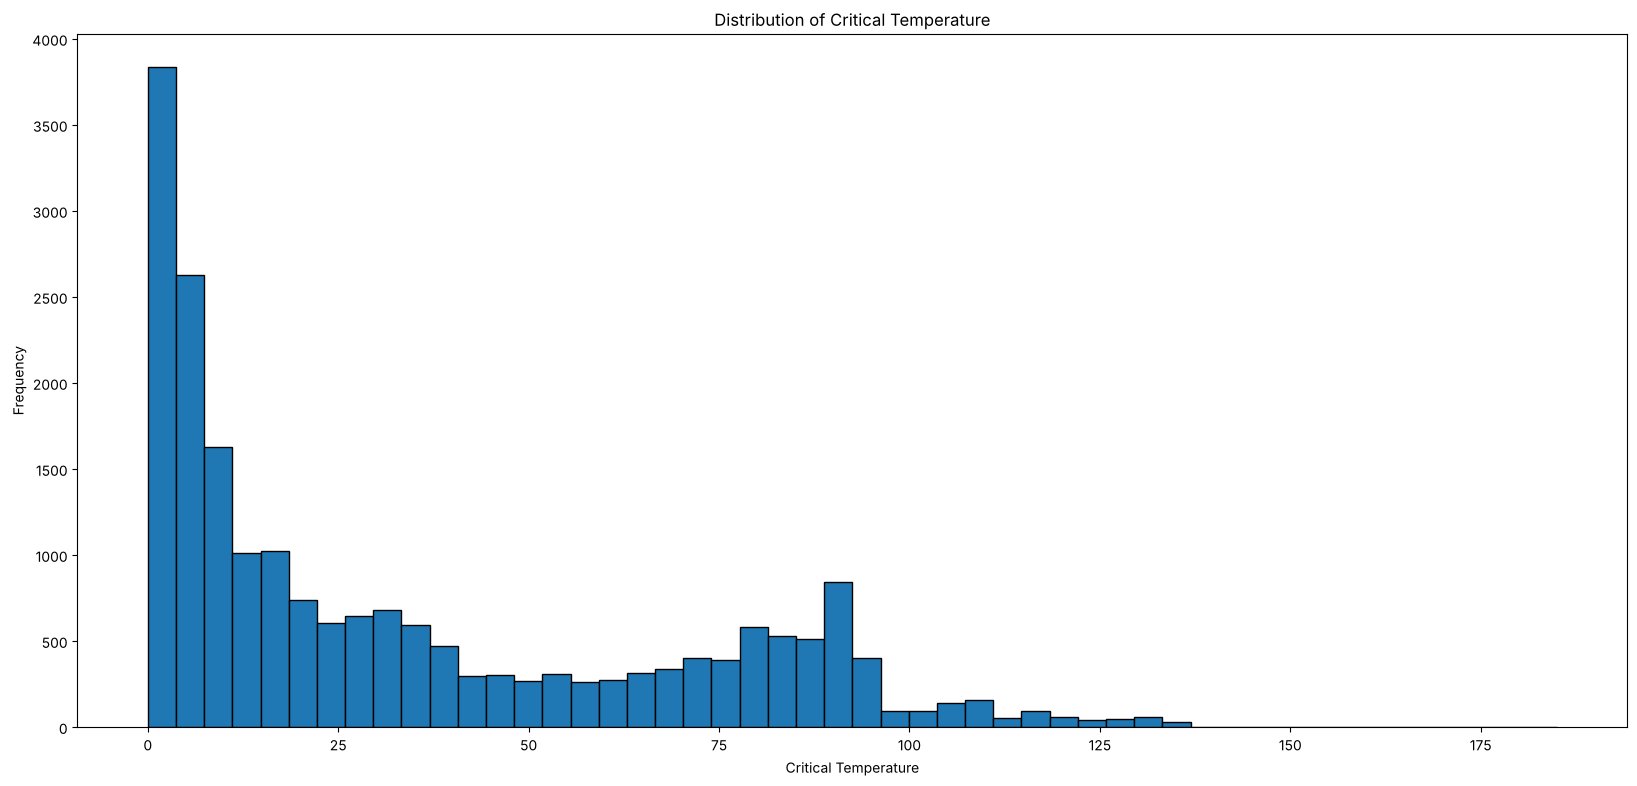

In [6]:
# Histogram of the target variable
plt.figure(figsize=(20,9))
plt.hist(y_train_full, bins=50, edgecolor='black')
plt.title('Distribution of Critical Temperature')
plt.xlabel('Critical Temperature')
plt.ylabel('Frequency')
plt.show()

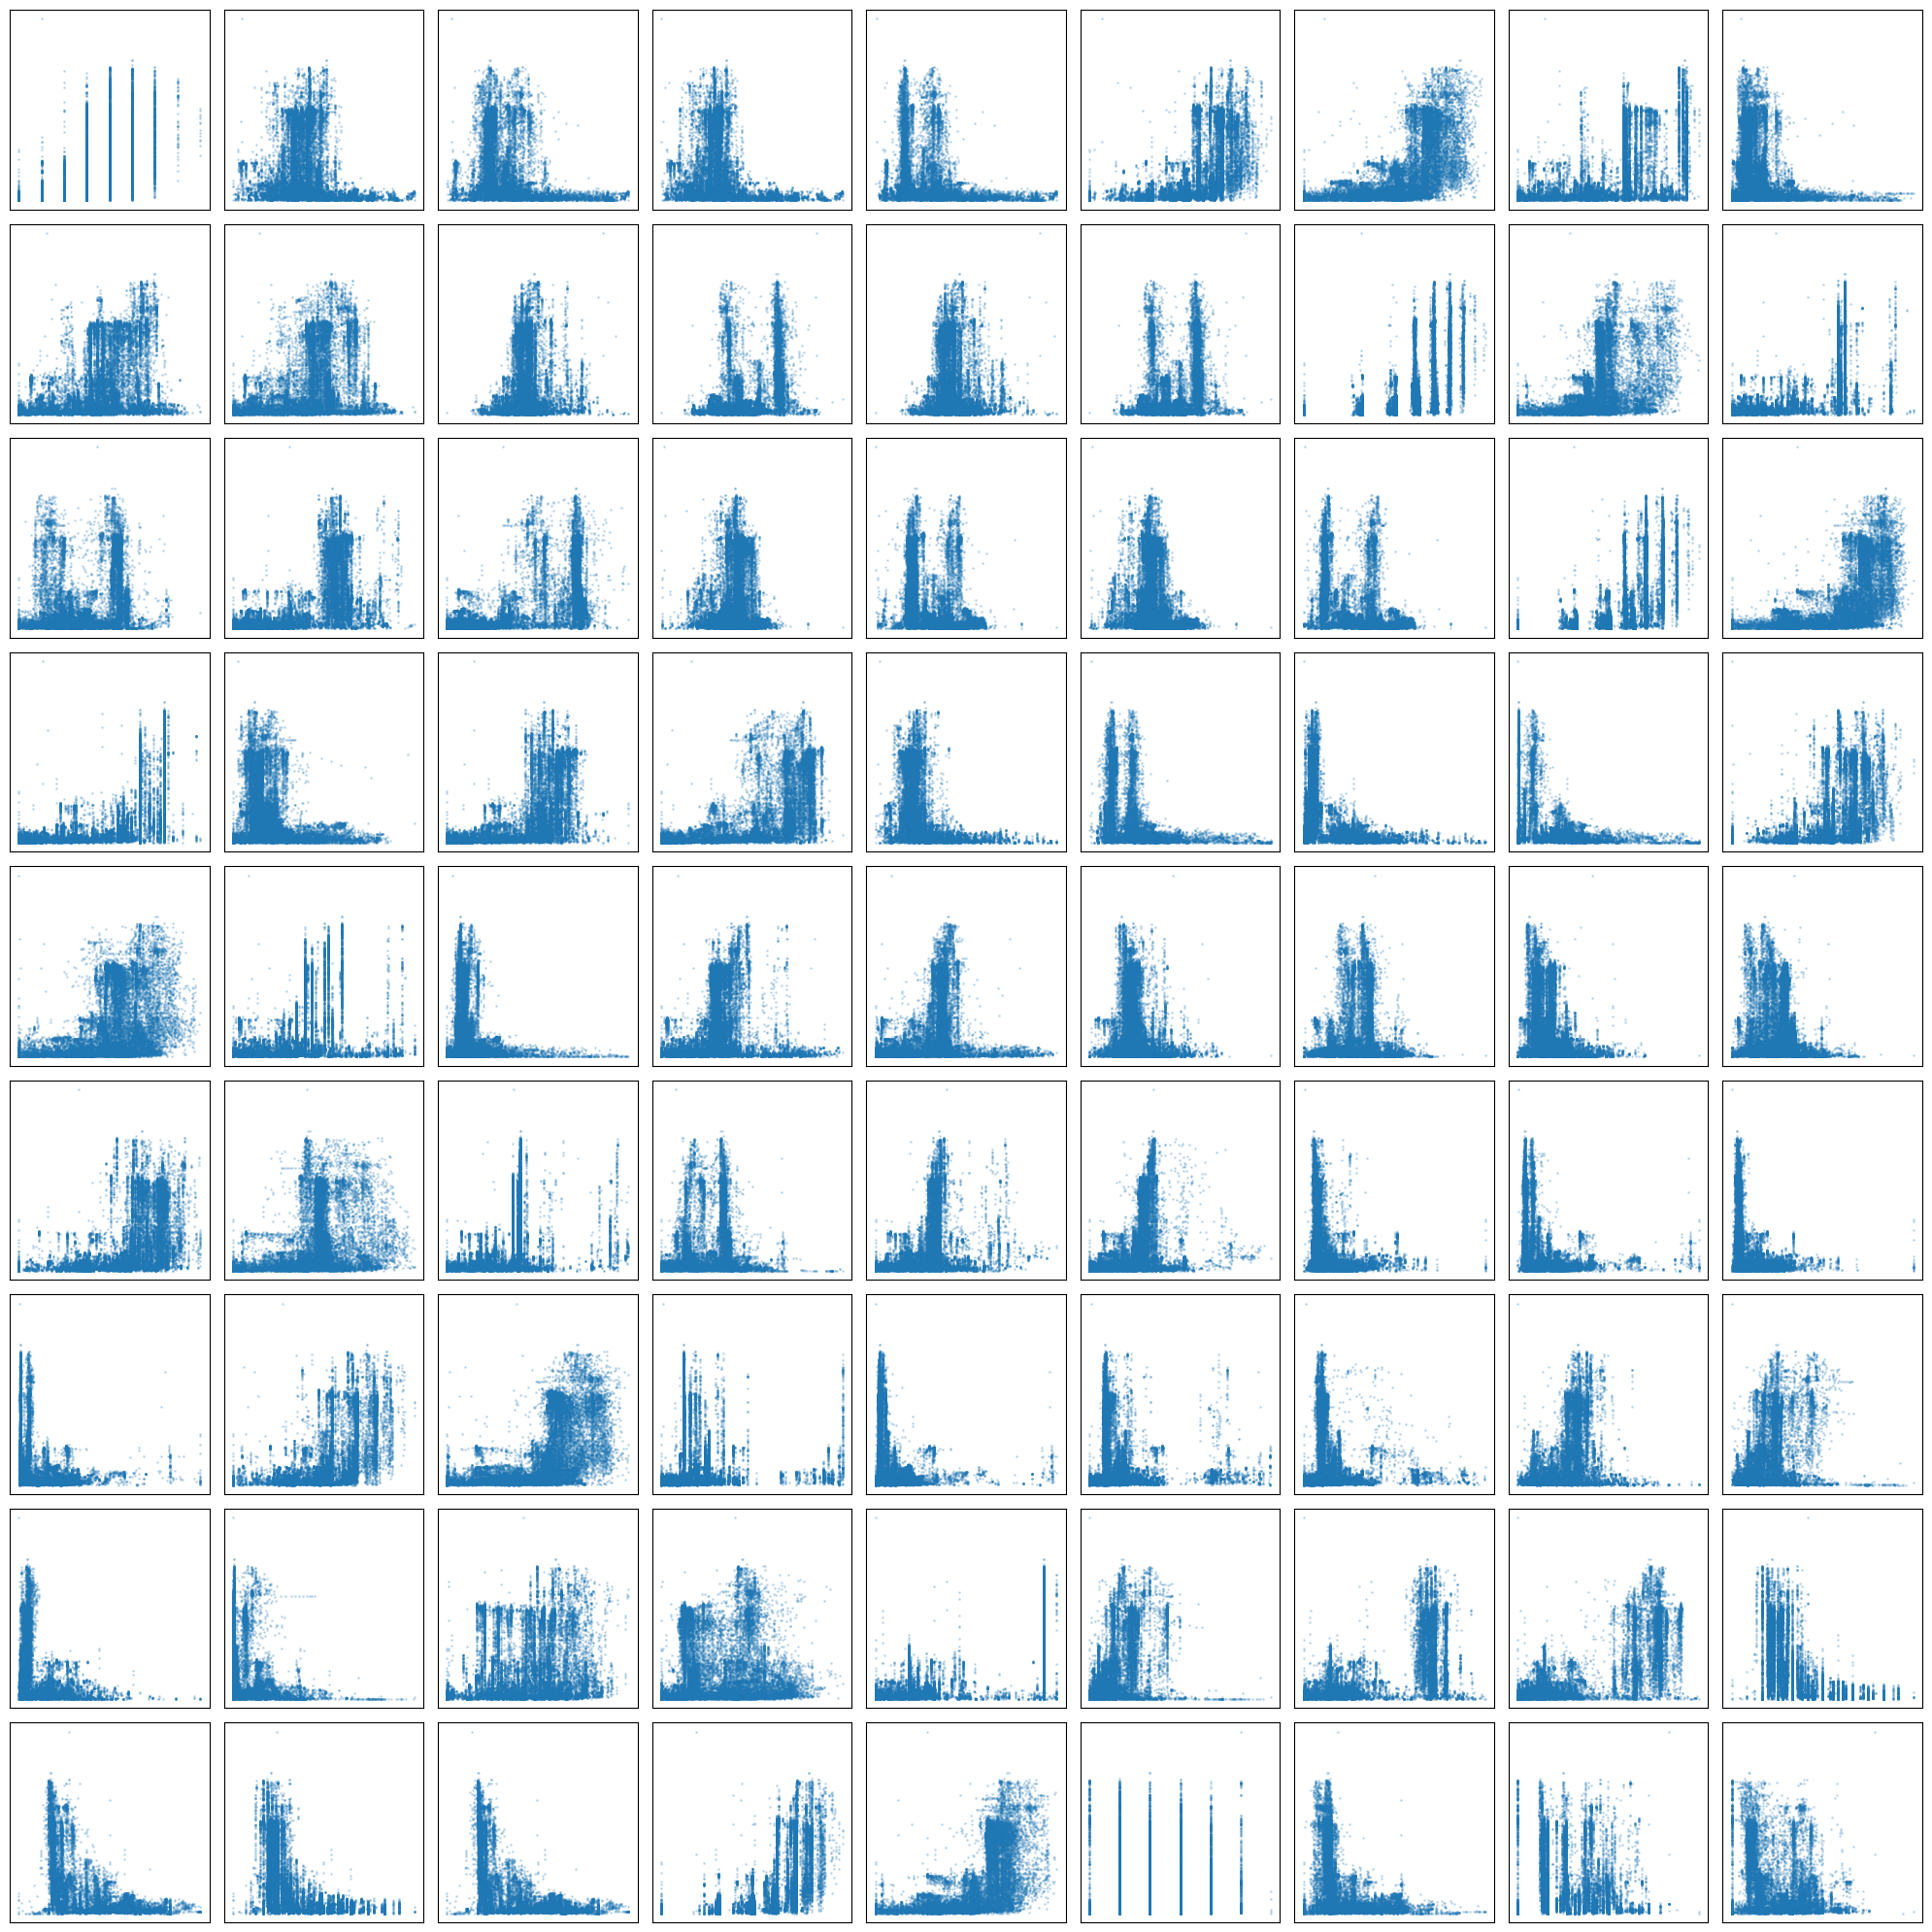

In [7]:
# Scatter plots of the target variable vs. features
fig, axes = plt.subplots(9, 9, figsize=(20, 20))
axes = axes.flatten()

for i in range(X_train_full_raw.shape[1]):
    # Using small marker size and alpha blending as requested
    axes[i].scatter(X_train_full_raw[:, i], y_train_full, s=1, alpha=0.2)
    axes[i].set_xticks([]) # Removing ticks for a cleaner grid view
    axes[i].set_yticks([])

plt.tight_layout()
plt.show()


In [8]:
# Normalize
def normalize(X_train, X_test):
    '''Normalizes data using training set statistics.'''
    mean = np.mean(X_train, axis=0)
    std = np.std(X_train, axis=0)
    
    # Prevent division by zero in case of constant features
    std[std == 0] = 1e-8 
    
    X_train_norm = (X_train - mean) / std
    X_test_norm = (X_test - mean) / std
    
    return X_train_norm, X_test_norm, mean, std

# Apply normalization to the datasets
X_train, X_test, mean_small, std_small = normalize(X_train_raw, X_test_raw)
X_train_full, X_test_full, mean_full, std_full = normalize(X_train_full_raw, X_test_raw)

# Print the means and standard variations of the first five features
print("First 5 features mean (before):", np.mean(X_train_full_raw[:, :5], axis=0))
print("First 5 features std (before):", np.std(X_train_full_raw[:, :5], axis=0))
print("First 5 features mean (after):", np.round(np.mean(X_train_full[:, :5], axis=0), 5))
print("First 5 features std (after):", np.round(np.std(X_train_full[:, :5], axis=0), 5))

First 5 features mean (before): [ 4.11221885 87.60808137 73.0498836  71.34256083 58.60335661]
First 5 features std (before): [ 1.43960483 29.70299734 33.56235885 31.0755541  36.73208566]
First 5 features mean (after): [-0. -0.  0.  0. -0.]
First 5 features std (after): [1. 1. 1. 1. 1.]


Which material properties may be useful for predicting superconductivity? What other observations can you make?

Visually, it is difficult to isolate a single property to predict superconductivity, as the scatter plots lack clear linear trends, I think it suggests that  complex, non-linear modeling will be required. Furthermore, the visualizations reveal several key patterns: a massive clustering of points at the bottom of the y-axis indicates that most materials have very low critical temperatures, which make  high-temperature superconductors rare outliers. Additionally, several plots display distinct vertical lines. It might show  that some features are discrete rather than continuous. Overall, the sheer volume of data causes heavy overplotting, emphasizing the highly non-linear and complex nature of the dataset.

## Task 2:  Implement your own OLS estimator

We want to use linear regression to predict the critical temperature. Implement the ordinary least squares estimator without regularization 'by hand':

$w = (X^TX)^{-1}X^Ty$

To make life a bit easier, we provide a function that can be used to plot regression results. In addition it computes the mean squared error and the squared correlation between the true and predicted values. 

In [9]:
def plot_regression_results(y_test, y_pred, weights):
    '''Produces three plots to analyze the results of linear regression:
        -True vs predicted
        -Raw residual histogram
        -Weight histogram

    Inputs:
        y_test: (n_observations,) numpy array with true values
        y_pred: (n_observations,) numpy array with predicted values
        weights: (n_weights) numpy array with regression weights'''

    print('MSE: ', mean_squared_error(y_test, y_pred))
    print('r^2: ', r2_score(y_test, y_pred))

    fig, ax = plt.subplots(1, 3, figsize=(9, 3))
    # predicted vs true
    ax[0].scatter(y_test, y_pred, s=2)
    ax[0].set_title('True vs. Predicted')
    ax[0].set_xlabel('True %s' % (target_clm))
    ax[0].set_ylabel('Predicted %s' % (target_clm))

    # residuals
    error = np.squeeze(np.array(y_test)) - np.squeeze(np.array(y_pred))
    ax[1].hist(np.array(error), bins=30)
    ax[1].set_title('Raw residuals')
    ax[1].set_xlabel('(true-predicted)')

    # weight histogram
    ax[2].hist(weights, bins=30)
    ax[2].set_title('weight histogram')

    plt.tight_layout()

As an example, we here show you how to use this function with random data. 

MSE:  17928.79570726673
r^2:  -13.313953173396845


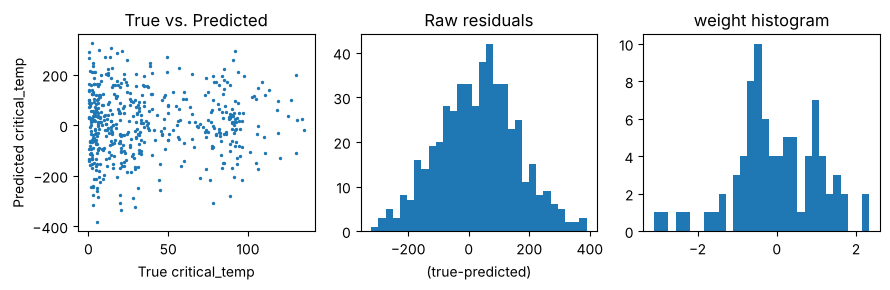

In [10]:
# weights is a vector of length 82: the first value is the intercept (beta0), then 81 coefficients
weights = np.random.randn(82)

# Model predictions on the test set
y_pred_testing = np.random.randn(y_test.size) * np.max(y_test)

plot_regression_results(y_test, y_pred_testing, weights)

Implement OLS linear regression yourself. Use `X_train` and `y_train` for estimating the weights and compute the MSE and $r^2$ from `X_test`. When you call our plotting function with the regression result, you should get mean squared error of 599.7.

In [11]:
def ols_regression(X_test, X_train, y_train):
    ones_train = np.ones((X_train.shape[0], 1))
    ones_test  = np.ones((X_test.shape[0], 1))
    X_train_b = np.hstack([ones_train, X_train])  # (200, 82)
    X_test_b  = np.hstack([ones_test,  X_test])   # (500, 82)

    # 2. w = (X^T X)^{-1} X^T y
    XtX = X_train_b.T @ X_train_b         # (82, 82)
    Xty = X_train_b.T @ y_train           # (82, 1)
    weights = np.linalg.solve(XtX, Xty)   

    y_pred = X_test_b @ weights

    return weights.flatten(), y_pred

MSE:  599.7397626161427
r^2:  0.5211810643348366


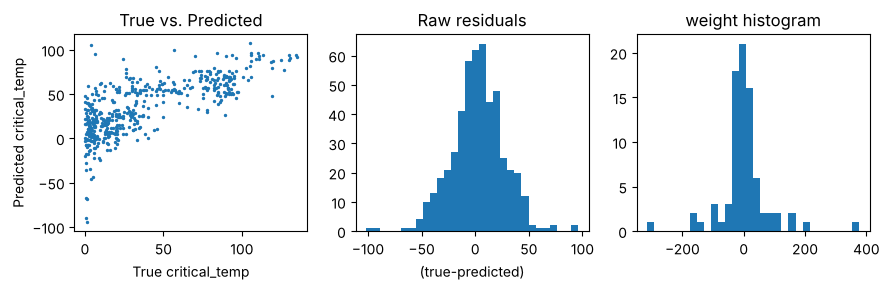

In [12]:
# Plots of the results
weights, y_pred = ols_regression(X_test, X_train, y_train)
plot_regression_results(y_test, y_pred, weights)

What do you observe? Is the linear regression model good?

The OLS regression yields an MSE of approximately 599.7, corresponding to an RMSE of around 24.5, which is considerable given that the critical temperature ranges roughly between 0 and 185. Looking at the True vs. Predicted plot, the points are loosely scattered around the diagonal rather than tightly following it. It might indicate  the model captures a general trend but makes large errors for many samples, especially for high critical temperatures. The r² score further confirms this: while it is positive and above zero, it falls notably short of 1, meaning the model explains only a moderate portion of the variance in the data. Overall, the linear regression model provides a baseline fit but is not particularly strong, likely because the relationship between the material features and critical temperature is complex and non-linear, which a simple linear model cannot fully capture.

## Task 3: Compare your implementation to sklearn

Now, familiarize yourself with the sklearn library. In the section on linear models:

https://scikit-learn.org/stable/modules/classes.html#module-sklearn.linear_model

you will find `sklearn.linear_model.LinearRegression`, the `sklearn` implementation of the OLS estimator. Use this sklearn class to implement OLS linear regression. Again obtain estimates of the weights on `X_train` and `y_train` and compute the MSE and $r^2$ on `X_test`.


In [13]:
def sklearn_regression(X_test, X_train, y_train):
    reg = linear_model.LinearRegression()
    reg.fit(X_train, y_train)
    y_pred = reg.predict(X_test)
    
    weights = np.concatenate([[reg.intercept_[0]], reg.coef_[0]])
    
    return weights, y_pred

MSE:  599.739762617794
r^2:  0.5211810643335182


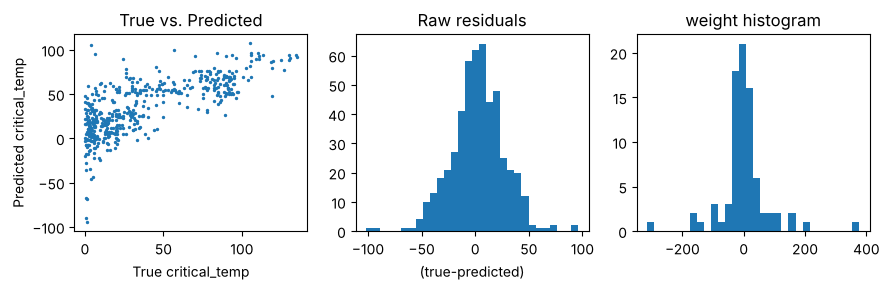

In [14]:
weights, y_pred = sklearn_regression(X_test, X_train, y_train)
plot_regression_results(y_test, y_pred, weights)

If you implemented everything correctly, the MSE is again 599.7.

Fit the model using the larger training set, `X_train_full` and `y_train_full`, and again evaluate on `X_test`.

MSE:  341.454872174021
r^2:  0.7273899970232713


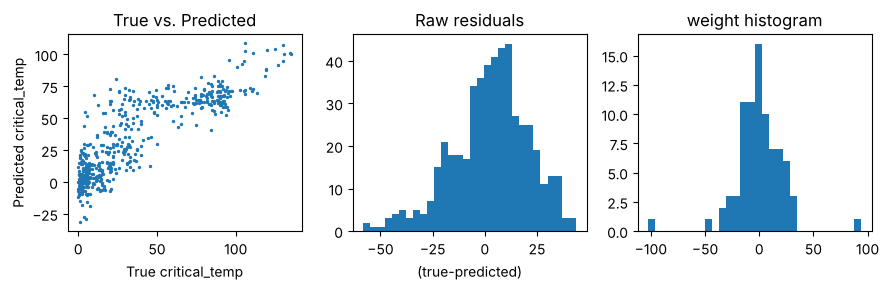

In [15]:
weights, y_pred = sklearn_regression(X_test, X_train_full, y_train_full)
plot_regression_results(y_test, y_pred, weights)



 How does test set performance change? What else changes?

When training on the full dataset instead of the small subset, the test set performance improves noticeably — the MSE drops significantly and the r² score increases, meaning the model explains a larger portion of the variance in the critical temperature. This is expected, as more training data allows the model to learn a better estimate of the true weights. In the True vs. Predicted plot, the points cluster more tightly around the diagonal. Additionally, the weight histogram changes: the weights become smaller and more concentrated around zero, since with more data the model is less prone to overfitting individual samples and finds a more stable, generalizable solution.

## Task 4: Regularization with ridge regression

We will now explore how a penalty term on the weights can improve the prediction quality for finite data sets. Implement the analytical solution of ridge regression 

$w = (X^TX + \alpha I_D)^{-1}X^Ty$


as a function that can take different values of $\alpha$, the regularization strength, as an input. In the lecture, this parameter was called $\lambda$, but this is a reserved keyword in Python.

*hint: don't penalize the intercept*

In [16]:
def ridge_regression(X_test, X_train, y_train, alpha):
    ones_train = np.ones((X_train.shape[0], 1))
    ones_test  = np.ones((X_test.shape[0], 1))
    X_train_b  = np.hstack([ones_train, X_train])  # (200, 82)
    X_test_b   = np.hstack([ones_test,  X_test])   # (500, 82)

    
    I = np.eye(X_train_b.shape[1])
    I[0, 0] = 0  

    # 3. w = (X^T X + alpha * I)^{-1} X^T y
    XtX = X_train_b.T @ X_train_b
    Xty = X_train_b.T @ y_train
    weights = np.linalg.solve(XtX + alpha * I, Xty)

    y_pred = X_test_b @ weights

    return weights.flatten(), y_pred

Run the ridge regression on `X_train` with an alpha value of 10 and plot the obtained weights.

MSE:  423.0879299058833
r^2:  0.6622159727968993


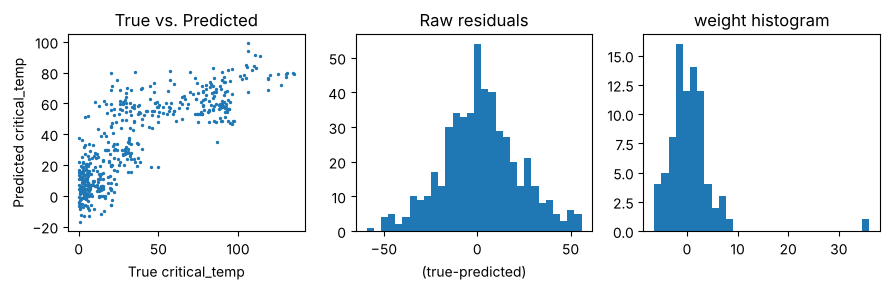

In [17]:
weights, y_pred = ridge_regression(X_test, X_train, y_train, alpha=10)
plot_regression_results(y_test, y_pred, weights)

Now test a range of log-spaced $\alpha\text{s}$ (~10-20), which cover several orders of magnitude, e.g. from 10^-7 to 10^7. 

* For each $\alpha$, you will get one model with one set of weights. 
* For each model, compute the error on the test set. 

Store both the errors and weights of all models for later use. You can use the function `mean_squared_error` from sklearn (imported above) to compute the MSE.


In [18]:
alphas = np.logspace(-7, 7, 20)

all_weights = []
all_mse = []

for alpha in alphas:
    weights, y_pred = ridge_regression(X_test, X_train, y_train, alpha)
    all_weights.append(weights)
    all_mse.append(mean_squared_error(y_test, y_pred))

all_weights = np.array(all_weights)  # (20, 82)
all_mse     = np.array(all_mse)      # (20,)

Make a single plot that shows for each coefficient how it changes with $\alpha$, i.e. one line per coefficient. Also think about which scale is appropriate for your $\alpha$-axis. You can set this using `plt.xscale(...)`.

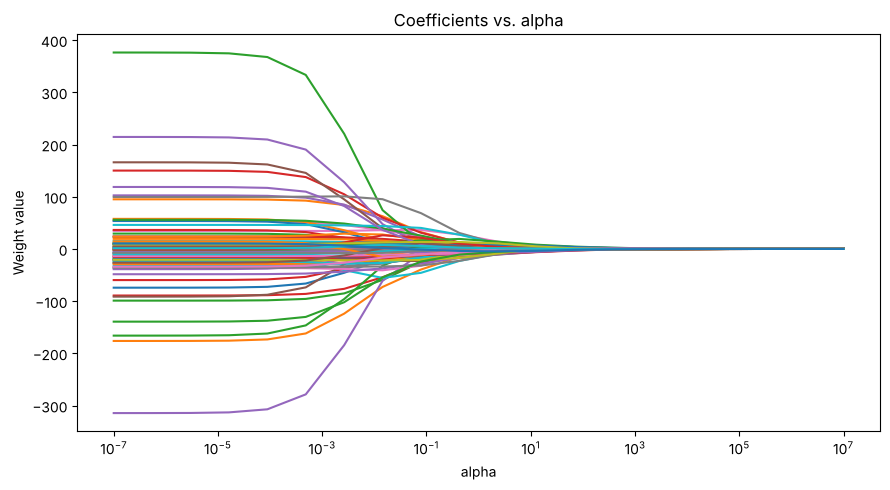

In [19]:
plt.figure(figsize=(9, 5))
plt.plot(alphas, all_weights[:, 1:])  
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Weight value')
plt.title('Coefficients vs. alpha')
plt.tight_layout()
plt.show()

Why are the values of the weights largest on the left? Do they all change monotonically? 

On the left side of the plot, alpha is very small and the regularization has almost no effect, so the weights are free to take large values — similar to the unregularized OLS solution. As alpha increases, the penalty term forces all weights closer to zero, so their magnitudes decrease. Not all weights change monotonically: some coefficients may first increase slightly before decreasing, depending on the correlation structure of the features.

Plot how the performance (i.e. the error) changes as a function of $\alpha$. As a sanity check, the MSE value for very small $\alpha$ should be close to the test-set MSE of the unregularized solution, i.e. 599.

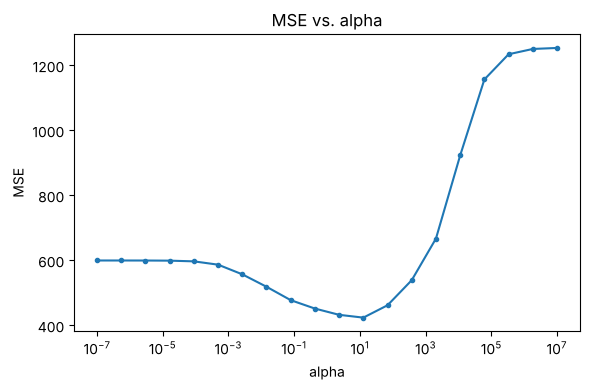

In [20]:
plt.figure(figsize=(6, 4))
plt.plot(alphas, all_mse, '.-')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('MSE')
plt.title('MSE vs. alpha')
plt.tight_layout()
plt.show()

Which value of $\alpha$ gives the minimum MSE? Is it better than the unregularized model? Why should the curve reach ~600 on the left?

The minimum MSE is achieved at an intermediate value of alpha, which can be read off the plot. This value gives a lower MSE than the unregularized OLS solution, showing that regularization helps generalization on the small training set. On the left side of the curve, alpha approaches zero and ridge regression converges to the OLS solution, so the MSE naturally approaches the unregularized test MSE of approximately 599.7.

Now implement the same model using sklearn. Use the `linear_model.Ridge` object to do so.


In [21]:
def ridge_regression_sklearn(X_test, X_train, y_train, alpha):
    reg = linear_model.Ridge(alpha=alpha)
    reg.fit(X_train, y_train.ravel())  # y_train'i 1D yap
    y_pred = reg.predict(X_test)
    
    weights = np.concatenate([[reg.intercept_], reg.coef_.flatten()])
    
    return weights, y_pred



This time, only plot how the performance changes as a function of $\alpha$. 

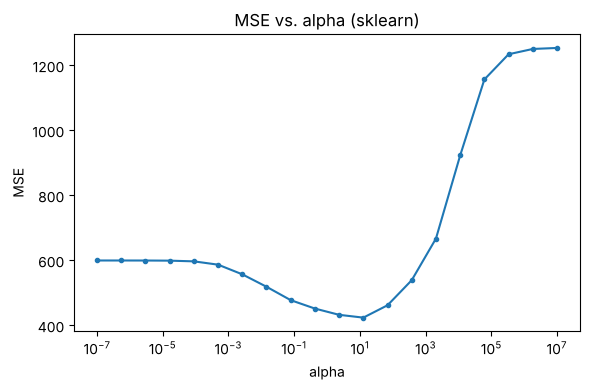

In [22]:
# Plot of MSE  vs. alphas
all_mse_sklearn = []
for alpha in alphas:
    _, y_pred = ridge_regression_sklearn(X_test, X_train, y_train, alpha)
    all_mse_sklearn.append(mean_squared_error(y_test, y_pred))

plt.figure(figsize=(6, 4))
plt.plot(alphas, all_mse_sklearn, '.-')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('MSE')
plt.title('MSE vs. alpha (sklearn)')
plt.tight_layout()
plt.show()

Note: Don't worry if the curve is not exactly identical to the one you got above. The loss function we wrote down in the lecture  has $\alpha$ defined a bit differently compared to sklearn. However, qualitatively it should look the same.

## Task 5: Cross-validation

Until now, we always estimated the error on the test set directly. However, we typically do not want to tune hyperparameters of our inference algorithms like $\alpha$ on the test set, as this may lead to overfitting. Therefore, we tune them on the training set using cross-validation. As discussed in the lecture, the training data is here split in `n_folds`-ways, where each of the folds serves as a held-out dataset in turn and the model is always trained on the remaining data. Implement a function that performs cross-validation for the ridge regression parameter $\alpha$. You can reuse functions written above.

In [23]:
def ridgeCV(X, y, n_folds, alphas):
    cv_results_mse = np.zeros((n_folds, len(alphas)))
    np.random.seed(seed=2)

    
    idx = np.random.permutation(X.shape[0])
    folds = np.array_split(idx, n_folds)

    for fold_i in range(n_folds):
        # Validation fold
        val_idx   = folds[fold_i]
        train_idx = np.concatenate([folds[j] for j in range(n_folds) if j != fold_i])

        X_val, y_val     = X[val_idx], y[val_idx]
        X_tr,  y_tr      = X[train_idx], y[train_idx]

        for alpha_i, alpha in enumerate(alphas):
            _, y_pred = ridge_regression(X_val, X_tr, y_tr, alpha)
            cv_results_mse[fold_i, alpha_i] = mean_squared_error(y_val, y_pred)

    return cv_results_mse

Now we run 10-fold cross-validation using the training data of a range of $\alpha$s.

In [24]:
alphas = np.logspace(-7, 7, 100)
mse_cv = ridgeCV(X_train, y_train, n_folds=10, alphas=alphas)

We plot the MSE trace for each fold separately:

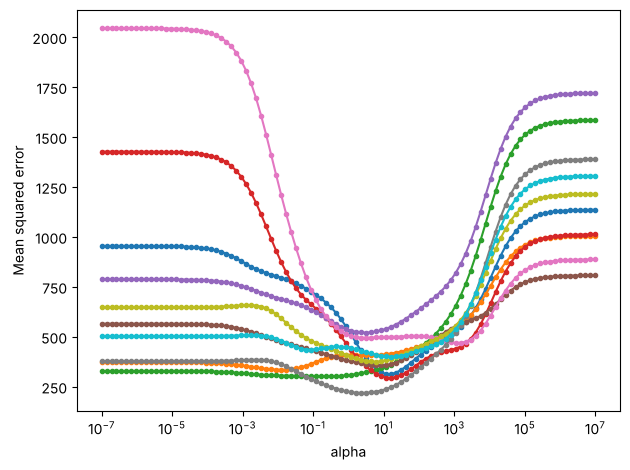

In [25]:
plt.plot(alphas, mse_cv.T, '.-')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Mean squared error')
plt.tight_layout()

We also plot the average across folds:

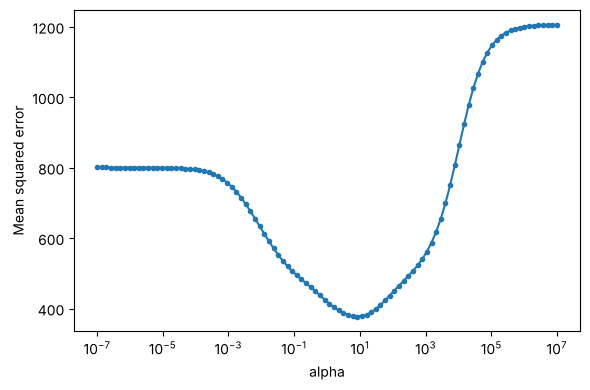

In [26]:
plt.figure(figsize=(6, 4))
plt.plot(alphas, np.mean(mse_cv, axis=0), '.-')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Mean squared error')
plt.tight_layout()

What is the optimal $\alpha$? Is it similar to the one found on the test set? Do the cross-validation MSE and the test-set MSE match well or differ strongly?

The optimal alpha found via cross-validation is the one minimizing the mean CV MSE, which can be read from the plot. It is generally close to the alpha that minimized the test-set MSE in Task 4, which confirms that cross-validation is a reliable way to select hyperparameters without touching the test set. The CV MSE values tend to be somewhat higher than the test-set MSE, since each fold trains on less data than the full training set, but the overall trend and optimal alpha are consistent.

We will now run cross-validation on the full training data. This will take a moment, depending on the speed of your computer. Afterwards, we will again plot the mean CV curves for the full data set (blue) and the small data set (orange).

In [27]:
alphas = np.logspace(-7, 7, 100)
mse_cv_full = ridgeCV(X_train_full, y_train_full, n_folds=10, alphas=alphas)

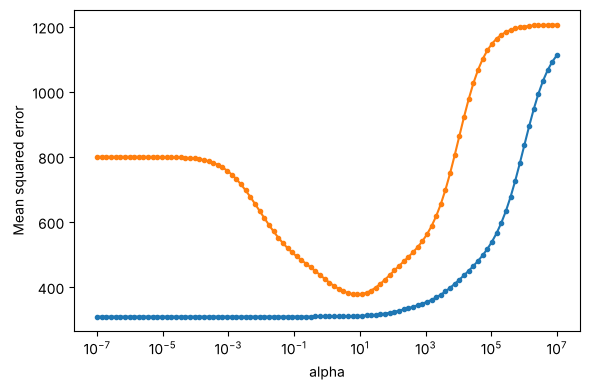

In [28]:
plt.figure(figsize=(6, 4))
plt.plot(alphas, np.mean(mse_cv_full, axis=0), '.-')
plt.plot(alphas, np.mean(mse_cv, axis=0), '.-')
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Mean squared error')
plt.tight_layout()

We zoom in on the blue curve to the very left:

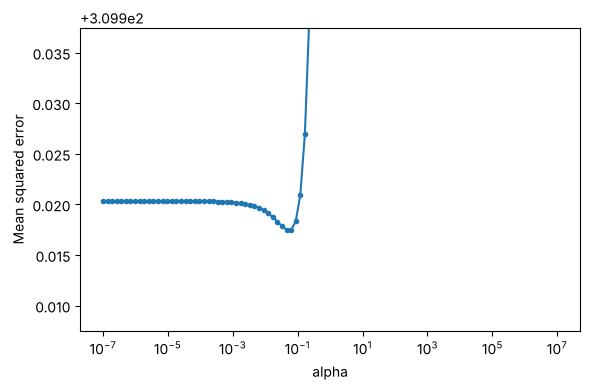

In [29]:
plt.figure(figsize=(6, 4))
plt.plot(alphas, np.mean(mse_cv_full, axis=0), '.-')
plt.xscale('log')
minValue = np.min(np.mean(mse_cv_full, axis=0))
plt.ylim([minValue-.01, minValue+.02])
plt.xlabel('alpha')
plt.ylabel('Mean squared error')
plt.tight_layout()

Why does the CV curve on the full data set look so different? What is the optimal value of $\alpha$ and why is it so much smaller than on the small training set?

With the full training set, the model already has enough data to estimate the weights reliably, so it needs much less regularization. The optimal alpha is therefore much smaller,close to zero,because the large amount of data naturally prevents overfitting. The CV curve also becomes much flatter on the left side, meaning performance is stable across a wide range of small alpha values. On the small training set, regularization was essential to compensate for the limited data, which is why a larger alpha was needed.